# Tech Challenge Fase 1: triagem de risco de alteração glicêmica

Modelo de classificação binária com dados do BRFSS 2015 (CDC). Ele apoia um questionário
respondido pelo paciente na sala de espera. O resultado vai para o médico, que tem a palavra final.
O modelo é uma ferramenta de **triagem**, não de diagnóstico.

# 1. Dados e Modelos

- **Fonte:** BRFSS 2015, pesquisa telefônica autodeclarada do CDC (441.456 pessoas, 330 colunas).
- **Público do produto:** pacientes **sem** diagnóstico prévio de diabetes.
- **Alvo:** alteração glicêmica atual ou passada (diabetes, gestacional ou pré-diabetes).
- **Métrica principal:** recall da classe positiva. Um falso positivo custa uma glicemia de jejum;
  um falso negativo adia um diagnóstico.
- **Seleção de colunas:** das 330 originais ficaram 10 features. Saíram colunas administrativas,
  módulos opcionais (69–100% vazios), variáveis que só existem para quem já é diabético e variáveis
  que o paciente não saberia responder. Uma variável por tema, preferindo as calculadas pelo CDC.

In [61]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
import seaborn as sb           
from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, recall_score, roc_auc_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier


## 1.1 Visualização das colunas dos dados brutos 

Como na fase inicial ficou complicado visualizar todas as colunas porque o pandas restringe por padrão a quantidade de colunas, foi necessário a configuração para retirar essa restrição e mostrar todas as colunas disponíveis. Nesse contexto, o Clauce Code ajudou na segmentação e agrupamento das colunas para que seleção de quais colunas utilizar se tornasse mais fácil. 

In [62]:
def encontrar_raiz(marcador: str = "requirements.txt") -> Path:
    """Sobe a partir do diretório atual até achar a pasta que contém o marcador."""
    atual = Path.cwd().resolve()
    for pasta in [atual, *atual.parents]:
        
        if (pasta / marcador).exists():
            return pasta
    raise FileNotFoundError(
        f"'{marcador}' não foi encontrado a partir de {atual}. "
        "Execute o notebook de dentro do projeto TC1."
    )


ROOT = encontrar_raiz()
XPT = ROOT / "dataset" / "raw" / "LLCP2015.XPT"
RECORTE = ROOT / "dataset" / "processed" / "brfss2015_recorte.parquet"
FIGURAS = ROOT / "reports" / "figures"

In [63]:
ALVO = "DIABETE3"  # 1 = sim, 2 = só na gravidez, 3 = não, 4 = pré-diabetes, 7 = não sabe, 9 = recusou

FEATURES = [
    "_AGEG5YR",  # faixas de 5 anos: 1 = 18–24 ... 13 = 80+, 14 = ausente
    "SEX",       # 1 = masculino, 2 = feminino
    "_BMI5",     # IMC com 2 casas decimais implícitas (2534 = 25,34); vazio = ausente
    "_SMOKER3",  # 1 = todo dia, 2 = alguns dias, 3 = ex-fumante, 4 = nunca fumou, 9 = ausente
    "EXERANY2",  # 1 = sim, 2 = não, 7 = não sabe, 9 = recusou (invertido em relação ao _RFDRHV5)
    "_RFDRHV5",  # bebedor pesado: 1 = não, 2 = sim, 9 = ausente
    "_RFCHOL",   # colesterol alto: 1 = não, 2 = sim, 9 = ausente, vazio = não mediu
    "_RFHYPE5",  # pressão alta: 1 = não, 2 = sim, 9 = ausente
    "GENHLTH",   # 1 = excelente ... 5 = ruim, 7 = não sabe, 9 = recusou
    "DIFFWALK",  # dificuldade para andar: 1 = sim, 2 = não, 7 = não sabe, 9 = recusou
]

## 1.2 Carga e primeira exploração

O XPT bruto tem 1,1 GB e fica fora do Git. Ele só é lido se o recorte ainda não existir.
O recorte tem 2 MB e fica versionado, então o notebook roda sem baixar nada.

In [64]:
if not RECORTE.exists():
    bruto = pd.read_sas(XPT, format="xport", encoding="latin-1")
    bruto[[ALVO, *FEATURES]].to_parquet(RECORTE)
    del bruto

df = pd.read_parquet(RECORTE)
df.shape

(441456, 11)

In [65]:
df.head()

,DIABETE3,_AGEG5YR,SEX,_BMI5,_SMOKER3,EXERANY2,_RFDRHV5,_RFCHOL,_RFHYPE5,GENHLTH,DIFFWALK
0,3.0,9.0,2.0,4018.0,3.0,2.0,1.0,2.0,2.0,5.0,1.0
1,3.0,7.0,2.0,2509.0,1.0,1.0,1.0,1.0,1.0,3.0,2.0
2,3.0,11.0,2.0,2204.0,9.0,NaN,9.0,2.0,1.0,4.0,NaN
3,3.0,9.0,2.0,2819.0,4.0,2.0,1.0,2.0,2.0,5.0,1.0
4,3.0,9.0,2.0,2437.0,4.0,2.0,1.0,1.0,1.0,5.0,2.0


## 1.3 Preparando o alvo

### DIABETE3
- Limpeza dos nulo
- Transformação de DIABETE3 (1,2,3,4) para ALVO (1,0) onde 1,2 e4 viram 1(true) e 3 vira 0 (falso)
- Remove a coluna DIABETE3

In [66]:
df[ALVO].value_counts(dropna=False)

DIABETE3
3.0    372104
1.0     57256
4.0      7690
2.0      3608
7.0       598
9.0       193
NaN         7
Name: count, dtype: int64

In [67]:
dados = df[df[ALVO].isin([1, 2, 3, 4])].copy()
dados["alvo"] = dados[ALVO].isin([1, 2, 4]).astype(int)  # True/False vira 1/0
dados = dados.drop(columns=ALVO)

In [68]:
dados["alvo"].mean()

np.float64(0.15557189475738556)

### Primeira avaliação do alvo

Aqui podemos observar que em torno de 15% dos registros da nossa base tem alteração glicemica confirmada.

# 2 Exploração dos dados

In [69]:
dados.describe()

,_AGEG5YR,SEX,_BMI5,_SMOKER3,EXERANY2,_RFDRHV5,_RFCHOL,_RFHYPE5,GENHLTH,DIFFWALK,alvo
count,440658.000000,440658.000000,404467.000000,440658.000000,405330.000000,440658.000000,381712.000000,440658.000000,440656.000000,428369.000000,440658.000000
mean,7.802048,1.576706,2804.024534,3.548353,1.311309,1.514694,1.491200,1.426381,2.577614,1.856192,0.155572
std,3.494521,0.494082,665.327551,1.462561,0.724207,1.871490,0.871711,0.635965,1.116700,0.575894,0.362449
min,1.000000,1.000000,1202.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,5.000000,1.000000,2373.000000,3.000000,1.000000,1.000000,1.000000,1.000000,2.000000,2.000000,0.000000
50%,8.000000,2.000000,2695.000000,4.000000,1.000000,1.000000,1.000000,1.000000,2.000000,2.000000,0.000000
75%,10.000000,2.000000,3090.000000,4.000000,2.000000,1.000000,2.000000,2.000000,3.000000,2.000000,0.000000
max,14.000000,2.000000,9995.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,1.000000


Text(0.5, 0, 'IMC (kg/m²)')

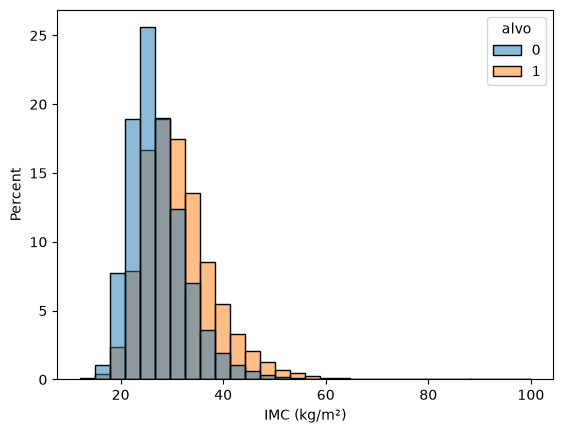

In [71]:
ax = sb.histplot(data=dados, x=dados["_BMI5"] / 100, hue="alvo",
                 stat="percent", common_norm=False, bins=30)
ax.set_xlabel("IMC (kg/m²)")

In [73]:
faixas = pd.cut(dados["_BMI5"] / 100,
                bins=[0, 18.5, 25, 30, 35, 40, 100],
                right=False)

prevalencia = dados.groupby(faixas, observed=True)["alvo"].agg(
    prevalencia="mean", n="count")
prevalencia

,prevalencia,n
_BMI5,,
"[0.0, 18.5)",0.060701,6705
"[18.5, 25.0)",0.074876,131257
"[25.0, 30.0)",0.139537,146807
"[30.0, 35.0)",0.230023,73197
"[35.0, 40.0)",0.308771,27875
"[40.0, 100.0)",0.365994,18626


In [74]:
contagem = pd.crosstab(faixas, dados["alvo"])
contagem


alvo,0,1
_BMI5,,
"[0.0, 18.5)",6298,407
"[18.5, 25.0)",121429,9828
"[25.0, 30.0)",126322,20485
"[30.0, 35.0)",56360,16837
"[35.0, 40.0)",19268,8607
"[40.0, 100.0)",11809,6817


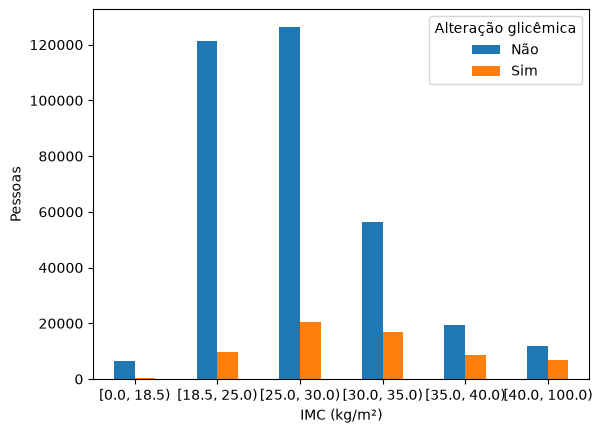

In [75]:
ax = contagem.plot(kind="bar", xlabel="IMC (kg/m²)", ylabel="Pessoas", rot=0)
ax.legend(title="Alteração glicêmica", labels=["Não", "Sim"])


Foi um grande desafio aprender a falar corretamente sobre a análise gráfica durante a exploração do dados. Porque quando afimado que: "Quanto maior o indice de massa corporal maior a CHANCE de ter alteração glicêmica." Isso pode soar como causa.
A afirmação adequada ao estudo científico dos dados seria: "Quanto maior a faixa de IMC, maior a prevalência de alteração glicêmica na amostra: de 6,1% (IMC < 18,5) a 36,6% (IMC ≥ 40). A relação é uma associação e não comprova causa. Como a maioria das pessoas não tem alteração mesmo na faixa mais alta, o IMC sozinho não basta para a triagem."

### Descoberta: os hábitos e o momento do diagnóstico

O BRFSS retrata o hábito **atual**, e o diagnóstico pode ter acontecido anos antes. As análises abaixo comparam a prevalência do alvo dentro de cada faixa etária, para separar o efeito da idade.

Por exemplo, uma pessoa pode ter bebido alcool por muito anos e depois ter sido diagnoticada com diabetes anos antes da pesquisa, e no momento de responder a pesquisa, respondeu que NÃO bebe alcool constantemente.

In [76]:
FAIXAS = ["18–24", "25–29", "30–34", "35–39", "40–44", "45–49", "50–54",
          "55–59", "60–64", "65–69", "70–74", "75–79", "80+"]  # códigos 1 a 13 do _AGEG5YR


def prevalencia_por_idade(df, coluna, validos, rotulos):
    """Prevalência do alvo por faixa etária e pelos grupos de `coluna`.

    validos: códigos da coluna que entram (ex.: [1, 2])
    rotulos: nomes dos grupos, NA ORDEM dos códigos (ex.: ["Sim", "Não"])
    """
    d = df[[ALVO, "_AGEG5YR", coluna]].copy()
    d = d[d[ALVO].isin([1, 2, 3, 4])]
    d["alvo"] = d[ALVO].isin([1, 2, 4]).astype(int)
    d = d[d[coluna].isin(validos)]
    d = d[d["_AGEG5YR"].isin(range(1, 14))]

    tab = d.groupby(["_AGEG5YR", coluna])["alvo"].mean().unstack()
    tab.columns = rotulos
    return tab


def plot_prevalencia_por_idade(tab, titulo, arquivo):
    """Plota a tabela de `prevalencia_por_idade` e salva a figura em reports/figures."""
    ax = tab.plot(marker="o", figsize=(9, 5))
    ax.set_xticks(range(1, 14))  # o índice da tabela são os próprios códigos 1 a 13
    ax.set_xticklabels(FAIXAS, rotation=45)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_xlabel("Faixa etária")
    ax.set_ylabel("Prevalência de alteração glicêmica")
    ax.set_title(titulo)
    ax.grid(alpha=0.3)
    plt.savefig(FIGURAS / arquivo, dpi=150, bbox_inches="tight")
    plt.show()

### Será que tem alguma relação entre o consumo pesado de álcool e a alteração glicemica?

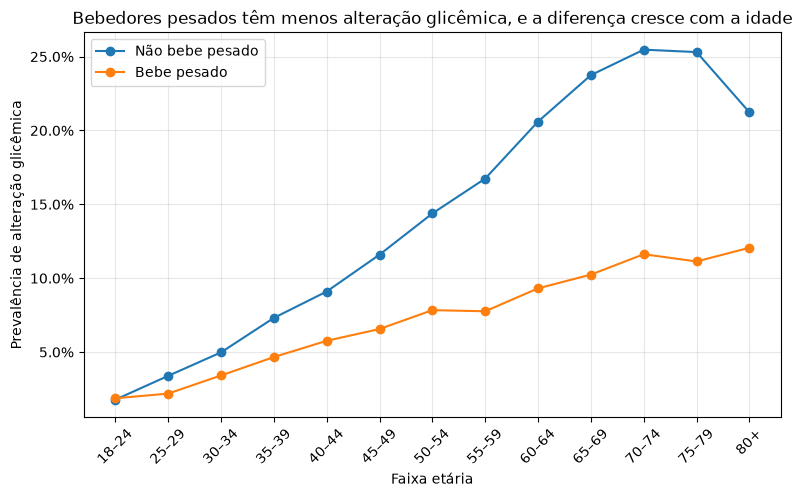

,Não bebe pesado,Bebe pesado
_AGEG5YR,,
1.0,0.018,0.019
2.0,0.034,0.022
3.0,0.050,0.034
4.0,0.073,0.047
5.0,0.091,0.058
6.0,0.116,0.066
7.0,0.144,0.078
8.0,0.167,0.078
9.0,0.206,0.093


In [77]:
tab_alcool = prevalencia_por_idade(df, "_RFDRHV5", [1, 2], ["Não bebe pesado", "Bebe pesado"])
plot_prevalencia_por_idade(
    tab_alcool,
    "Bebedores pesados têm menos alteração glicêmica, e a diferença cresce com a idade",
    "alcool_vs_idade.png",
)
tab_alcool.round(3)

**Álcool.** Ao contrário do esperado, bebedores pesados têm menos da metade da prevalência (7,4% contra
16,2%). A diferença persiste dentro das faixas etárias, exceto aos 18–24 anos, quando os grupos são
iguais (1,8% e 1,9%), e cresce com a idade. O padrão é coerente com a **causalidade reversa**: quem
recebe o diagnóstico tende a mudar de hábito. É uma hipótese, porque o dado é uma foto de um único
momento e não permite comprová-la.

A idade está muito mais associada ao alvo (1,8% → 25%) do que o álcool (até ~2,3× dentro da mesma faixa,
e só 5% da população). Hipótese a verificar com o SHAP na seção 9.

### Será que tem alguma relação entre a atividade física e a alteração glicemica?

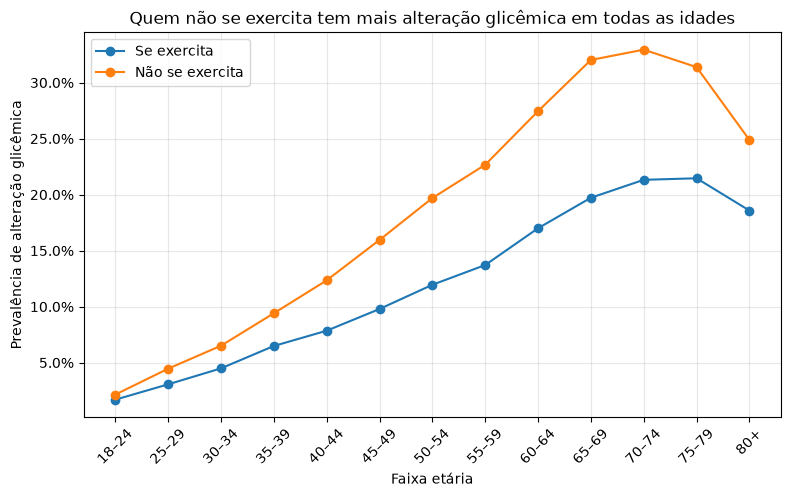

,Se exercita,Não se exercita
_AGEG5YR,,
1.0,0.017,0.021
2.0,0.031,0.045
3.0,0.045,0.065
4.0,0.065,0.094
5.0,0.079,0.123
6.0,0.098,0.160
7.0,0.120,0.197
8.0,0.137,0.227
9.0,0.170,0.274


In [78]:
tab_exercicio = prevalencia_por_idade(df, "EXERANY2", [1, 2], ["Se exercita", "Não se exercita"])
plot_prevalencia_por_idade(
    tab_exercicio,
    "Quem não se exercita tem mais alteração glicêmica em todas as idades",
    "exercicio_vs_idade.png",
)
tab_exercicio.round(3)

**Exercício.** Aqui o resultado confirma o esperado, em todas as faixas. No início da idade adulta a
diferença é pequena, mas já existe (1,7% e 2,1%), e aumenta à medida que a idade avança. Diferente do
álcool, ela aparece antes dos diagnósticos se acumularem.

**Consequência para o modelo.** O treino retrata muitos diabéticos **depois** do diagnóstico, mas o
produto atende quem **ainda não** foi diagnosticado. Isso é uma limitação documentada: o efeito das
variáveis de hábito deve ser lido como associação, nunca como causa.

# 3. Preparação dos dados

## 3.1 Etapas comuns aos dois modelos

In [ ]:
dados["_BMI5"] = dados["_BMI5"] / 100
dados["_BMI5"].describe()

In [ ]:
dados["_RFCHOL"].isnull().sum()  # 1 = não, 2 = sim, 9 = ausente, vazio = não mediu

In [ ]:
dados["_RFCHOL"] = dados["_RFCHOL"].fillna(3)    
dados["_RFCHOL"].isnull().sum()        

## 3.2 Preparação por modelo

As etapas acima valem para os dois modelos. A partir daqui, cada um recebe os dados de um jeito:

| | Regressão Logística | Random Forest |
|---|---|---|
| **Códigos 7, 9 e 14** | viram vazio e são imputados | ficam como estão, como uma resposta própria |
| **Vazios** | IMC: mediana; demais: mais frequente | IMC: mediana; demais: mais frequente |
| **Categóricas** | One-Hot Encoding | códigos originais, sem one-hot |
| **IMC** | `StandardScaler` | sem escala |

A Regressão Logística soma e multiplica os valores, então os códigos não podem entrar como números.
O Random Forest só faz cortes do tipo "maior ou menor", então consegue separar os códigos sozinho.

In [ ]:
# Duas cópias com as mesmas linhas: só o tratamento das colunas muda entre elas
df_reglog = dados.copy()
df_randfor = dados.copy()

In [ ]:
# Só na Regressão Logística: 7, 9 e 14 significam "não sabe", "recusou" ou "ausente", não quantidades.
# A troca é uma regra fixa, que não aprende nada dos dados, por isso pode vir antes do split.
CODIGOS_AUSENTES = {
    "_AGEG5YR": [14],
    "_SMOKER3": [9],
    "_RFDRHV5": [9],
    "_RFHYPE5": [9],
    "_RFCHOL": [9],
    "EXERANY2": [7, 9],
    "GENHLTH": [7, 9],
    "DIFFWALK": [7, 9],
}

for coluna, codigos in CODIGOS_AUSENTES.items():
    df_reglog[coluna] = df_reglog[coluna].replace(codigos, np.nan)

In [ ]:
# Usa df_reglog porque, na correlação, os códigos 7, 9 e 14 seriam lidos como quantidades
correlacao = df_reglog.corr()

plt.figure(figsize=(10, 8))
sb.heatmap(correlacao, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlação entre as variáveis")
plt.savefig(FIGURAS / "correlacao.png", dpi=150, bbox_inches="tight")
plt.show()


## 5. Separação treino, validação e teste

Como vamos precisar de 3 conjuntos de dados, treino, teste e validação, vamos fazer duas separações ficando com 60% para treino, 20% para teste e 20% para validação. No segundo split foi utilizado 0,25 para o tamanho da base de teste porque precisamo de 20% sobre a base inicial.

In [ ]:

#Separando os dados
x = df_reglog.drop(columns=['alvo'])
y = df_reglog['alvo'] 

X_treino_tmp, X_teste, y_treino_tmp, y_teste = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

X_treino, X_val, y_treino, y_val = train_test_split(
    X_treino_tmp, y_treino_tmp, test_size=0.25, random_state=42, stratify=y_treino_tmp
)


### Verificando o tamanho das bases

No bloco abaixo verificamos se o tamanho das bases ficou de acordo com o objetivo: 60% treino, 20% teste e 20% validação.

In [ ]:
# Tamanho de cada conjunto em relação ao total
for nome, conjunto in [("treino", X_treino), ("validação", X_val), ("teste", X_teste)]:
    print(f"{nome}: {len(conjunto)} linhas ({len(conjunto) / len(x):.1%})")

# Proporção da classe positiva em cada conjunto (estratificação)
print(y.mean(), y_treino.mean(), y_val.mean(), y_teste.mean())

# Nenhuma linha perdida ou repetida entre os conjuntos
assert len(X_treino) + len(X_val) + len(X_teste) == len(x)
assert X_treino.index.intersection(X_val.index).empty
assert X_treino.index.intersection(X_teste.index).empty
assert X_val.index.intersection(X_teste.index).empty


### Mesmas linhas para o Random Forest

O split é feito uma única vez. O Random Forest usa as mesmas linhas de cada conjunto, escolhidas pelo
índice, para que a comparação entre os modelos seja justa e nenhuma linha de validação ou teste entre no treino.

In [ ]:
colunas_rf = df_randfor.drop(columns=["alvo"])

X_treino_rf = colunas_rf.loc[X_treino.index]
X_val_rf = colunas_rf.loc[X_val.index]
X_teste_rf = colunas_rf.loc[X_teste.index]

# Confere se as linhas e a ordem coincidem com as da Regressão Logística
assert X_treino_rf.index.equals(X_treino.index)
assert X_val_rf.index.equals(X_val.index)
assert X_teste_rf.index.equals(X_teste.index)

## 6. Pipelines de pré-processamento

Cada modelo tem o seu pipeline, ajustado só com o treino. O IMC é a única variável numérica. A imputação
usa a mediana porque o IMC tem cauda longa à direita, e a média sofre mais com os valores extremos.

In [ ]:
NUMERICAS = ["_BMI5"]
CATEGORICAS = [c for c in FEATURES if c not in NUMERICAS]

# Regressão Logística: IMC na mesma escala das demais colunas
pipeline_num = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("escala", StandardScaler()),
])

# Regressão Logística: uma coluna 0/1 por categoria, para o código não ser lido como quantidade
pipeline_cat = Pipeline([
    ("imputador", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessador_reglog = ColumnTransformer([
    ("num", pipeline_num, NUMERICAS),
    ("cat", pipeline_cat, CATEGORICAS),
])

# Random Forest: só preenche os vazios. Os cortes da árvore dispensam escala e one-hot.
preprocessador_randfor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), NUMERICAS),
    ("cat", SimpleImputer(strategy="most_frequent"), CATEGORICAS),
])

## 7. Modelos

## Modelo 1 utilizado: Regressão Logística

In [ ]:
modelo1 = Pipeline([
    ("preprocessador", preprocessador_reglog),
    ("classificador", LogisticRegression(max_iter=1000, random_state=42)),
])

modelo1.fit(X_treino, y_treino)

pred_val = modelo1.predict(X_val)
prob_val = modelo1.predict_proba(X_val)[:, 1]

pd.DataFrame({
    "f1": f1_score(y_val, pred_val),
    "recall": recall_score(y_val, pred_val),
    "roc_auc": roc_auc_score(y_val, prob_val),
}, index=["validação"])

In [ ]:
modelo2 = Pipeline([
    ("preprocessador", preprocessador_randfor),
    ("classificador", RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)),
])

modelo2.fit(X_treino_rf, y_treino)

pred_val = modelo2.predict(X_val_rf)
prob_val = modelo2.predict_proba(X_val_rf)[:, 1]

pd.DataFrame({
    "f1": f1_score(y_val, pred_val),
    "recall": recall_score(y_val, pred_val),
    "roc_auc": roc_auc_score(y_val, prob_val),
}, index=["validação"])

## 8. Limiar e avaliação final


In [ ]:
from sklearn.metrics import precision_recall_curve

melhor = modelo1  # modelo escolhido: Regressão Logística
RECALL_MINIMO = 0.80

prob_val = melhor.predict_proba(X_val)[:, 1]
precisoes, recalls, limiares = precision_recall_curve(y_val, prob_val)

# Último índice que ainda mantém o recall mínimo, ou seja, o limiar mais alto
indice = np.where(recalls[:-1] >= RECALL_MINIMO)[0][-1]
limiar = limiares[indice]
print(f"Limiar: {limiar:.3f} | recall: {recalls[indice]:.3f} | precisão: {precisoes[indice]:.3f}")


In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report

prob = melhor.predict_proba(X_teste)[:, 1]
pred = (prob >= limiar).astype(int)

print(classification_report(y_teste, pred, digits=3))
print(f"AUC: {roc_auc_score(y_teste, prob):.3f} | accuracy: {accuracy_score(y_teste, pred):.3f} | sinalizados: {pred.mean():.1%}")

ConfusionMatrixDisplay.from_predictions(y_teste, pred, display_labels=["Sem alteração", "Com alteração"])
plt.savefig(FIGURAS / "matriz_confusao.png", dpi=150, bbox_inches="tight")
plt.show()


## 9. Interpretação


In [ ]:
from sklearn.inspection import permutation_importance

# Mede quanto a AUC cai ao embaralhar cada coluna (amostra de 10 mil linhas, por tempo)
amostra = X_val.sample(10000, random_state=42)
imp = permutation_importance(melhor, amostra, y_val.loc[amostra.index], scoring="roc_auc",
                             n_repeats=5, random_state=42, n_jobs=-1)
importancia = pd.Series(imp.importances_mean, index=amostra.columns).sort_values()

importancia.plot.barh(figsize=(8, 5), xlabel="Queda na AUC ao embaralhar a coluna",
                      title="Feature importance por permutação (validação)")
plt.savefig(FIGURAS / "feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()


In [ ]:
import shap

pre = melhor.named_steps["preprocessador"]
clf = melhor.named_steps["classificador"]
nomes = [n.split("__")[1] for n in pre.get_feature_names_out()]

# Amostras de 100 linhas (referência) e 2 mil (explicadas), para reduzir o tempo de cálculo
fundo = pre.transform(X_treino.sample(100, random_state=42))
X_shap = pre.transform(X_val.sample(2000, random_state=42))
valores = shap.LinearExplainer(clf, fundo)(X_shap)
valores.feature_names = nomes

# Soma as colunas one-hot para obter o efeito de cada variável original
grupo = [next(f for f in FEATURES if n.startswith(f)) for n in nomes]
shap_df = pd.DataFrame(valores.values, columns=nomes)
print(shap_df.T.groupby(grupo).sum().T.abs().mean().sort_values(ascending=False).round(3))

shap.summary_plot(valores, max_display=12, show=False)
plt.savefig(FIGURAS / "shap_resumo.png", dpi=150, bbox_inches="tight")
plt.show()


In [ ]:
from sklearn.metrics import precision_score

pred_val = (melhor.predict_proba(X_val)[:, 1] >= limiar).astype(int)

linhas = {}
for codigo, nome in [(1, "Homens"), (2, "Mulheres")]:
    filtro = (X_val["SEX"] == codigo).values
    linhas[nome] = {"recall": recall_score(y_val[filtro], pred_val[filtro]),
                    "precisão": precision_score(y_val[filtro], pred_val[filtro]),
                    "sinalizados": pred_val[filtro].mean()}
print(pd.DataFrame(linhas).T.round(3))

codigos_alvo = df.loc[X_val.index, ALVO].values
for codigo, nome in [(1, "Diabetes"), (2, "Gestacional"), (4, "Pré-diabetes"), (3, "Sem alteração")]:
    print(f"{nome}: {pred_val[codigos_alvo == codigo].mean():.1%} sinalizados")


### Interpretação do modelo (Regressão Logística, dados de validação)

**Variáveis mais importantes.** A permutação e o SHAP apontam as mesmas três primeiras: saúde geral
autoavaliada, idade e pressão alta. Colesterol e IMC vêm logo depois e trocam de posição entre os métodos.
Sexo, tabagismo, exercício e dificuldade para andar pesam pouco quando as demais variáveis já estão no modelo.

**Direção dos efeitos, mantendo as demais variáveis iguais (odds ratio):**
- Saúde geral "ruim" contra "excelente": chance cerca de 6,3 vezes maior.
- Faixa de 70–74 anos contra 18–24: cerca de 5,1 vezes. O efeito cai no grupo 80+, possivelmente por viés de sobrevivência.
- Pressão alta: cerca de 2,0 vezes. Colesterol alto: cerca de 1,7 vez.
- Cada 5 pontos de IMC: cerca de 1,3 vez.
- Bebedor pesado: cerca de 0,5 vez.

**Hipóteses da exploração.** A idade pesa muito mais que o álcool. O álcool aparece reduzindo o risco, o que
não significa que beber proteja: o padrão é coerente com a causalidade reversa, pois quem recebe o diagnóstico
tende a mudar de hábito. O exercício pesa pouco no modelo (odds ratio de 1,08), embora a diferença tenha sido
clara na exploração. Parte desse efeito provavelmente é absorvida por saúde geral, IMC e idade.

**Ressalvas.** Os resultados mostram associação, não causa. O dado é de um único momento, e saúde geral e pressão
alta também podem refletir o próprio diagnóstico. "Colesterol sem medição" reduz o risco estimado (0,69 vez),
o que pode refletir menos acesso ao diagnóstico, e não menos doença.

**Equidade.** O modelo se comporta de forma parecida entre homens e mulheres (recall de 0,81 e 0,79, precisão
de 0,31 e 0,30). Já os casos gestacionais são pouco sinalizados: 31,9%, abaixo dos 34,0% do grupo sem alteração,
contra 84,2% em diabetes e 70,7% em pré-diabetes. Para esse grupo, o modelo praticamente não funciona como triagem.


## 10. Discussão crítica

O modelo serve apenas de apoio a triagem não como diagnóstico definitivo. Pois um ponto que pesa na qualidade dos resultados e aplicação real do sistema, é a causalidade reversa. Um paciente diagnosticado, tende a mudar os hábitos após o diagnótico, então ele responderá que sim, pratica atividade física, que não bebe álcool constantemente, mas possui diabetes diagnosticada.